# Round 1

### 2 products:
- Ash Coated Osmium
- Intarian Pepper Root

## Loading Data

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

price_files = {
  # Day # File
    -2: "data/prices_round_1_day_-2.csv",
    -1: "data/prices_round_1_day_-1.csv",
    0: "data/prices_round_1_day_0.csv"
}

trade_files = {
    -2: "data/trades_round_1_day_-2.csv",
    -1: "data/trades_round_1_day_-1.csv",
    0: "data/trades_round_1_day_0.csv"
}

# Load and offset timestamps by 1M steps
OFFSET = 1_000_000 # each day has 1 million steps
def read_prices(product: str):
        dfs = []
        for i, (day, pf) in enumerate(price_files.items()):
            df = pd.read_csv(pf, sep=';')
            df = df[df['product'] == product].copy()
            df['timestamp'] += i * OFFSET
            df['day'] = day
            dfs.append(df)
        return pd.concat(dfs, ignore_index=True).sort_values('timestamp')

def read_trades(symbol: str):
        dfs = []
        for i, (day, pf) in enumerate(trade_files.items()):
            df = pd.read_csv(pf, sep=';')
            df = df[df['symbol'] == symbol].copy()
            df['timestamp'] += i * OFFSET
            df['day'] = day
            dfs.append(df)
        return pd.concat(dfs, ignore_index=True).sort_values('timestamp')

# Combine
osmium_prices = read_prices('ASH_COATED_OSMIUM')
osmium_trades = read_trades('ASH_COATED_OSMIUM')
pepper_prices = read_prices('INTARIAN_PEPPER_ROOT')
pepper_trades = read_trades('INTARIAN_PEPPER_ROOT')

osmium_prices.head()


,day,timestamp,product,bid_price_1,bid_volume_1,bid_price_2,bid_volume_2,bid_price_3,bid_volume_3,ask_price_1,ask_volume_1,ask_price_2,ask_volume_2,ask_price_3,ask_volume_3,mid_price,profit_and_loss
0,-2,0,ASH_COATED_OSMIUM,NaN,NaN,NaN,NaN,NaN,NaN,10010.0,25.0,NaN,NaN,NaN,NaN,10010.0,0.0
1,-2,100,ASH_COATED_OSMIUM,9992.0,15.0,NaN,NaN,NaN,NaN,10008.0,15.0,10011.0,20.0,NaN,NaN,10000.0,0.0
2,-2,200,ASH_COATED_OSMIUM,9992.0,15.0,9989.0,30.0,NaN,NaN,10008.0,15.0,10010.0,30.0,NaN,NaN,10000.0,0.0
3,-2,300,ASH_COATED_OSMIUM,9992.0,13.0,9989.0,26.0,NaN,NaN,10008.0,13.0,10010.0,26.0,NaN,NaN,10000.0,0.0
4,-2,400,ASH_COATED_OSMIUM,9992.0,15.0,NaN,NaN,NaN,NaN,10008.0,15.0,10010.0,20.0,NaN,NaN,10000.0,0.0


Confirm data loaded:

In [43]:
osmium_prices.head()
pepper_prices.head()

,day,timestamp,product,bid_price_1,bid_volume_1,bid_price_2,bid_volume_2,bid_price_3,bid_volume_3,ask_price_1,ask_volume_1,ask_price_2,ask_volume_2,ask_price_3,ask_volume_3,mid_price,profit_and_loss
0,-2,0,INTARIAN_PEPPER_ROOT,9992.0,17.0,NaN,NaN,NaN,NaN,10005.0,9.0,10008.0,17.0,NaN,NaN,9998.5,0.0
1,-2,100,INTARIAN_PEPPER_ROOT,9995.0,11.0,9992.0,16.0,NaN,NaN,10006.0,11.0,10008.0,16.0,NaN,NaN,10000.5,0.0
2,-2,200,INTARIAN_PEPPER_ROOT,9995.0,12.0,NaN,NaN,NaN,NaN,10008.0,20.0,NaN,NaN,NaN,NaN,10001.5,0.0
3,-2,300,INTARIAN_PEPPER_ROOT,NaN,NaN,NaN,NaN,NaN,NaN,10006.0,10.0,10008.0,21.0,NaN,NaN,10006.0,0.0
4,-2,400,INTARIAN_PEPPER_ROOT,9992.0,20.0,NaN,NaN,NaN,NaN,10006.0,12.0,10008.0,20.0,NaN,NaN,9999.0,0.0


## Initial Price Analysis

<Axes: >

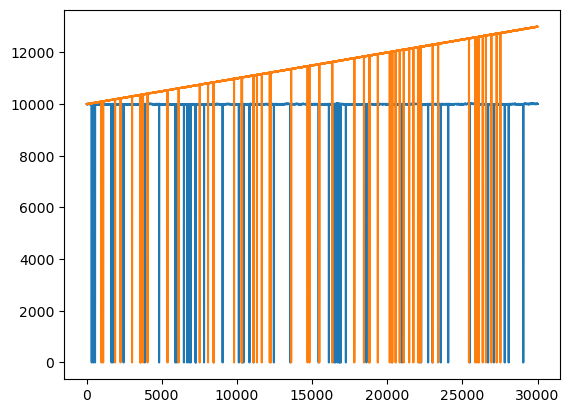

In [44]:
osmium_prices["mid_price"].plot()
pepper_prices["mid_price"].plot()

---
# Osmium

In [45]:
osmium_prices[["bid_price_3", "bid_price_2", "bid_price_1", "mid_price", "ask_price_1", "ask_price_2", "ask_price_3"]].describe().round(1)

,bid_price_3,bid_price_2,bid_price_1,mid_price,ask_price_1,ask_price_2,ask_price_3
count,779.0,19596.0,28796.0,30000.0,28799.0,19552.0,747.0
mean,9989.3,9989.8,9992.1,9983.9,10008.3,10010.6,10010.6
std,4.7,4.7,5.0,403.9,5.1,4.7,4.6
min,9976.0,9976.0,9976.0,0.0,9984.0,9992.0,9998.0
25%,9986.0,9987.0,9989.0,9997.0,10005.0,10007.0,10007.0
50%,9990.0,9990.0,9992.0,10000.5,10009.0,10011.0,10011.0
75%,9993.0,9993.0,9995.0,10003.5,10012.0,10014.0,10014.0
max,10004.0,10006.0,10014.0,10023.0,10026.0,10026.0,10025.0


The mid price is very volatile and has a standard deviation of >400! Much higher than the other quotes with a standard deviation of ~5. Additionally, we see that about 3% of the time, there is neither a buy or sell order available.

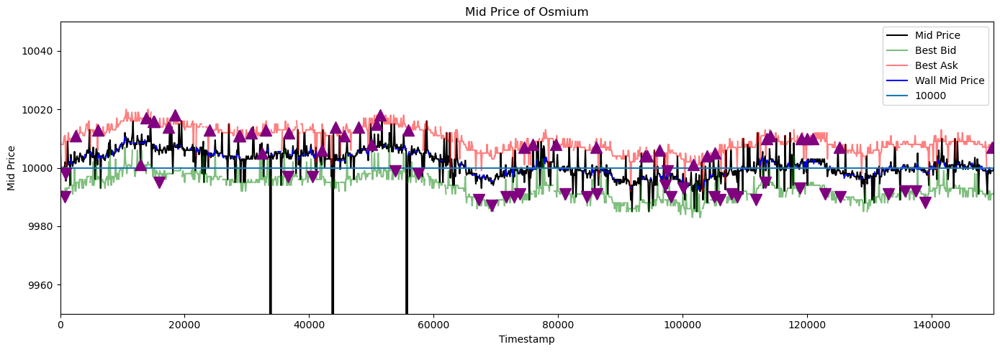

In [46]:
fig, ax = plt.subplots(figsize=(14, 5))
plt.title("Mid Price of Osmium")

plt.plot(osmium_prices['timestamp'], osmium_prices['mid_price'], label="Mid Price", color='black')
plt.plot(osmium_prices['timestamp'],osmium_prices['bid_price_1'], label="Best Bid", color='green', alpha=0.5)
plt.plot(osmium_prices['timestamp'],osmium_prices['ask_price_1'], label="Best Ask", color='red', alpha=0.5)
plt.plot(osmium_prices['timestamp'], (osmium_prices['bid_price_2']+osmium_prices['ask_price_2'])/2, label="Wall Mid Price", color='blue')
plt.axhline(10000,0,label="10000")


for trade in osmium_trades.itertuples():
    time = trade.timestamp
    price = trade.price
    mark = None
    if trade.price < 10000:
        mark = 'v'
    else:
        mark = '^'
    ax.plot(time, price, marker=mark, color='purple', ms=12)

plt.xlabel("Timestamp")
plt.ylabel("Mid Price")
plt.ylim(9950, 10050)

plt.xlim(0,150000)
plt.legend()
plt.tight_layout()

plt.show()

In [47]:
import plotly.express as px
df = osmium_prices
fig = px.line(df, x="timestamp", y=["bid_price_1","bid_price_2","bid_price_3","ask_price_1","ask_price_2","ask_price_3"], title="Time Series")
fig.show()

We initially observe that their is not a lot of liquidity in the osmium market. There are multiple periods showing no bid or ask orders in the market, causing the mid price to be extremely volatile. If we want to trade this asset, we need to find a way to not rely on the mid_price from the order book.

## Spread of Osmium

Spread analysis allows us to determine the feasibility of market making strategies that allow us to capture orders by beating the best orders while bidding below and asking above the fair value of the underlying asset. Having a large spread makes and asset a better candidate for this strategy.

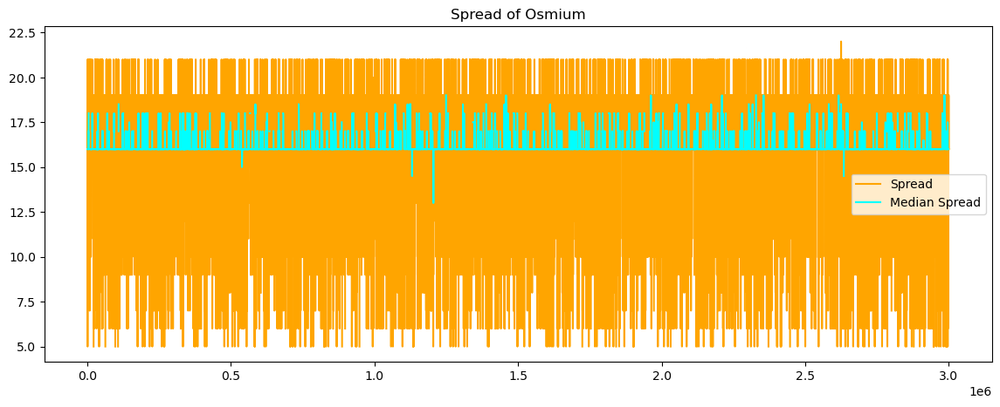

In [48]:
fig, ax = plt.subplots(figsize=(14, 5))
plt.title("Spread of Osmium")

osmium_prices["spread"] = osmium_prices["ask_price_1"] - osmium_prices["bid_price_1"]
plt.plot(osmium_prices['timestamp'], osmium_prices["spread"], label="Spread", color='orange')
plt.plot(osmium_prices['timestamp'], osmium_prices["spread"].rolling(window=10).median(), label="Median Spread", color='cyan')
plt.legend()
plt.show()

The spread is around 16 for Osmium.

---
# Pepper

In [49]:
pepper_prices[["bid_price_3", "bid_price_2", "bid_price_1", "mid_price", "ask_price_1", "ask_price_2", "ask_price_3"]].describe().round(1)

,bid_price_3,bid_price_2,bid_price_1,mid_price,ask_price_1,ask_price_2,ask_price_3
count,445.0,19413.0,28784.0,30000.0,28850.0,19531.0,467.0
mean,11558.5,11491.9,11494.6,11479.2,11507.5,11508.1,11483.4
std,856.4,865.5,865.6,993.2,866.7,864.9,864.1
min,9996.0,9992.0,9992.0,0.0,10002.0,10008.0,10013.0
25%,10801.0,10740.0,10744.8,10745.5,10756.0,10759.0,10762.5
50%,11615.0,11494.0,11496.0,11497.5,11508.0,11508.0,11431.0
75%,12284.0,12241.0,12244.0,12248.5,12258.8,12256.0,12234.5
max,12979.0,12989.0,12993.0,13007.0,13010.0,13010.0,12995.0


Pepper looks to be even more chaotic. All the prices have a standard deviation of almost 1,000! Let's look at the graph.

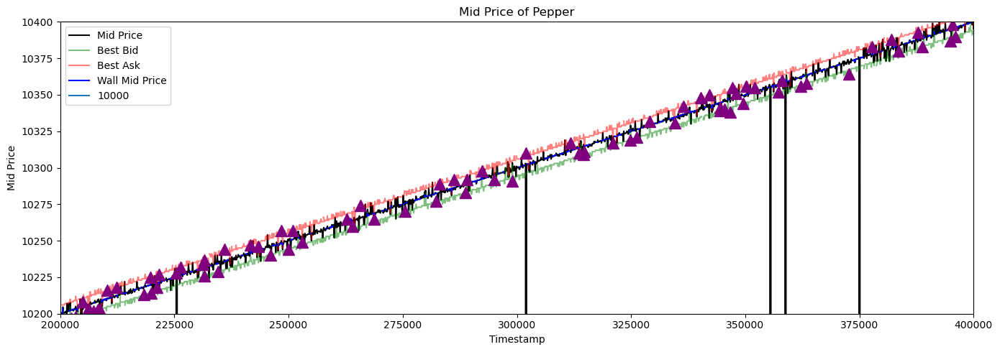

In [50]:
fig, ax = plt.subplots(figsize=(14, 5))
plt.title("Mid Price of Pepper")

plt.plot(pepper_prices['timestamp'], pepper_prices['mid_price'], label="Mid Price", color='black')
plt.plot(pepper_prices['timestamp'],pepper_prices['bid_price_1'], label="Best Bid", color='green', alpha=0.5)
plt.plot(pepper_prices['timestamp'],pepper_prices['ask_price_1'], label="Best Ask", color='red', alpha=0.5)
plt.plot(pepper_prices['timestamp'], (pepper_prices['bid_price_2']+pepper_prices['ask_price_2'])/2, label="Wall Mid Price", color='blue')
plt.axhline(10000,0,label="10000")


for trade in pepper_trades.itertuples():
    time = trade.timestamp
    price = trade.price
    mark = None
    if trade.price < 10000:
        mark = 'v'
    else:
        mark = '^'
    ax.plot(time, price, marker=mark, color='purple', ms=12)

plt.xlabel("Timestamp")
plt.ylabel("Mid Price")
plt.ylim(10200, 10400)

plt.xlim(200000,400000)
plt.legend()
plt.tight_layout()

plt.show()

We actually see with the visual that the price is more stable, following a positive linear relationship. While the initial data description suggested volatility, the visual shows the opposite.

In [51]:
df = pepper_prices
fig = px.line(df, x="timestamp", y=["bid_price_1","bid_price_2","bid_price_3","ask_price_1","ask_price_2","ask_price_3"], title="Time Series")
fig.show()

### Spread Analysis

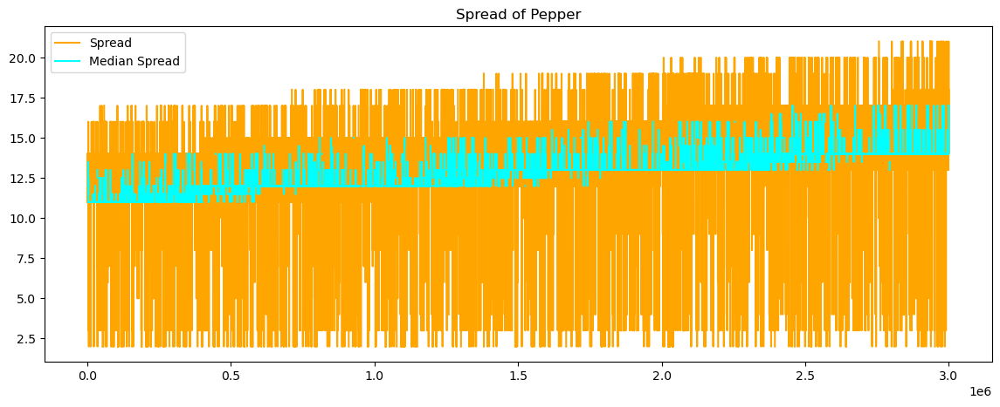

In [52]:
fig, ax = plt.subplots(figsize=(14, 5))
plt.title("Spread of Pepper")

pepper_prices["spread"] = pepper_prices["ask_price_1"] - pepper_prices["bid_price_1"]
plt.plot(pepper_prices['timestamp'], pepper_prices["spread"], label="Spread", color='orange')
plt.plot(pepper_prices['timestamp'], pepper_prices["spread"].rolling(window=10).median(), label="Median Spread", color='cyan')
# plt.axhline(pepper_prices["spread"].rolling(window=100).mean(), label="Average Spread", color='cyan')
plt.legend()
plt.show()

We see the spread  of pepper is consistently around 12.5 before later increasing.

In [53]:
pepper_trades["price"].describe()

count     1011.000000
mean     11495.941642
std        879.805548
min       9995.000000
25%      10736.000000
50%      11502.000000
75%      12251.000000
max      13005.000000
Name: price, dtype: float64

## Pepper Strategy

In [54]:
np.polyfit(pepper_prices["timestamp"],pepper_prices["mid_price"],1)

array([9.97465198e-04, 9.98304083e+03])

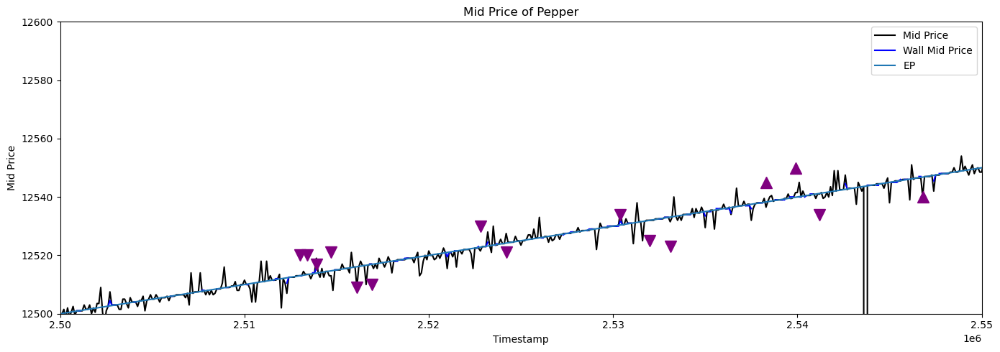

In [60]:
fig, ax = plt.subplots(figsize=(14, 5))
plt.title("Mid Price of Pepper")

plt.plot(pepper_prices['timestamp'], pepper_prices['mid_price'], label="Mid Price", color='black')
plt.plot(pepper_prices['timestamp'], (pepper_prices['bid_price_2']+pepper_prices['ask_price_2'])/2, label="Wall Mid Price", color='blue')
#plt.axhline(10000,0,label="10000")
# function EP = 0.00097465198x + 9983.04083
ep = 0.001*pepper_prices["timestamp"]+10000
plt.plot(pepper_prices['timestamp'],ep, label="EP")
for trade in pepper_trades.itertuples():
    time = trade.timestamp
    price = trade.price
    mark = None
    if trade.price < 12540:
        mark = 'v'
    else:
        mark = '^'
    ax.plot(time, price, marker=mark, color='purple', ms=12)

plt.xlabel("Timestamp")
plt.ylabel("Mid Price")
plt.xlim(2500000,2550000)
plt.ylim(12500,12600)
plt.legend()
plt.tight_layout()

plt.show()

<Axes: >

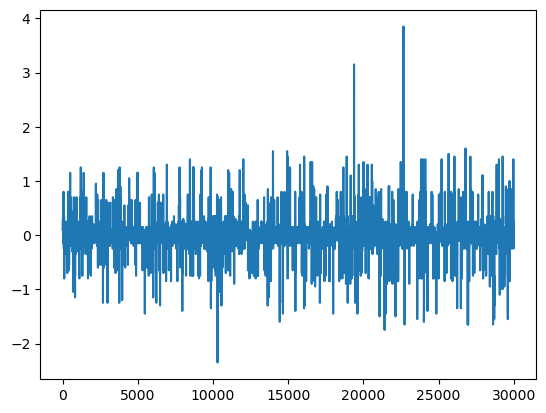

In [64]:
# Minimizing Error
error = ep - pepper_prices["mid_price"]
error.rolling(window=10).median().plot()

Our strategy here should be to buy our inventory limit of pepper and hold until the end.

But what if we try market taking / making where we have a strong bias against negative inventory? (we should always be close to or at max- only selling if we know we can buy back easily before the mid price exceeds what we sold it for)

In [70]:
pepper_trades["timestamp"].diff().median()

2200.0

There is about 2200 time units between a normal trade, so the price will increase by ~2.2 in this time.

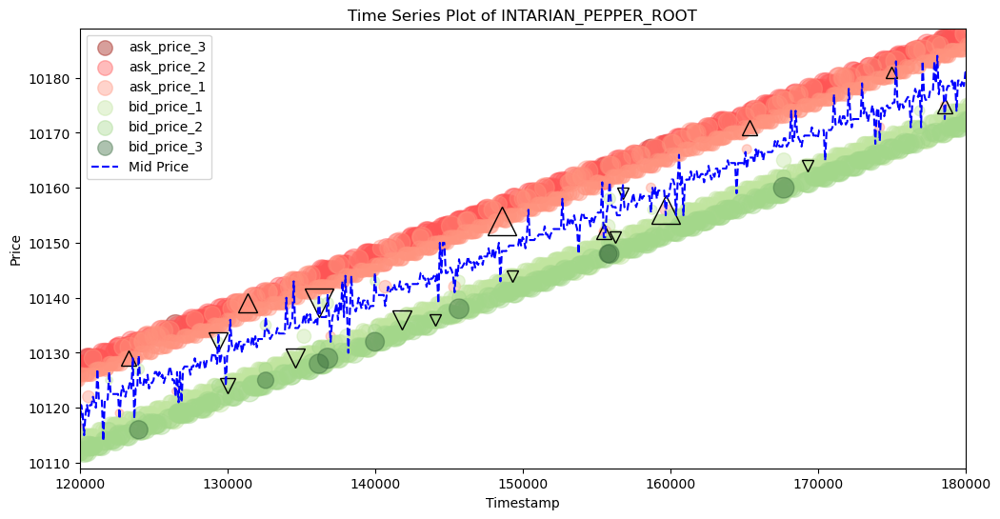

10100


/var/folders/n0/zqhkt25d7sv8fn8m4k9ggcc80000gn/T/ipykernel_13033/4266348107.py:3: FutureWarning:

Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead



In [ ]:
from imcplots import *
order_book_plot(pepper_prices, pepper_trades, xmin=120000, xmax=180000)
print(int(pepper_prices[pepper_prices['timestamp']==100000]['mid_price']))